Carga de librerías

In [104]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd


print("Python:", sys.version.split()[0])
print("Bibliotecas cargadas correctamente")

Python: 3.13.9
Bibliotecas cargadas correctamente


Carga de datos

In [105]:
from pathlib import Path

# Raíz del proyecto desde notebook
carpeta_actual = Path.cwd()
proyecto = (
    carpeta_actual.parent
    if carpeta_actual.name == "notebooks"
    else carpeta_actual
)

ruta_csv = proyecto / "data" / "raw" / "tfl_agosto2024.csv"

# Carga de datos csv
viajes = pd.read_csv(ruta_csv)

print(f"Viajes: {viajes.shape[0]:,}")
print(f"Columnas: {viajes.shape[1]}")
display(viajes.head())

Viajes: 411,370
Columnas: 11


,Number,Start date,Start station number,Start station,End date,End station number,End station,Bike number,Bike model,Total duration,Total duration (ms)
0,142043054,14/08/2024 23:59,22165,"Fisherman's Walk West, Canary Wharf",15/08/2024 00:40,200233,"South Quay East, Canary Wharf",59663,CLASSIC,40m 53s,2453526
1,142043055,14/08/2024 23:59,22159,"Ebury Bridge, Pimlico",15/08/2024 00:04,965,"Tachbrook Street, Victoria",57811,CLASSIC,4m 54s,294201
2,142043056,14/08/2024 23:59,22165,"Fisherman's Walk West, Canary Wharf",15/08/2024 00:47,200004,"Lightermans Road, Millwall",42113,CLASSIC,48m 24s,2904192
3,142043057,14/08/2024 23:59,1072,"Waterloo Station 3, Waterloo",15/08/2024 00:07,994,"Tanner Street, Bermondsey",60373,PBSC_EBIKE,8m 18s,498028
4,142043059,14/08/2024 23:59,300237,"Tate Modern, Bankside",15/08/2024 00:12,200206,"Chicheley Street, South Bank",51953,CLASSIC,12m 57s,777758


Calidad de los datos

In [106]:
# Tipo de datos y valores ausentes
resumen = pd.DataFrame({
    "tipo": viajes.dtypes.astype(str),
    "valores_ausentes": viajes.isna().sum()
})
display(resumen)

# Duplicidad de IDs
print("Identificadores duplicados:", viajes["Number"].duplicated().sum())

# Revisión de fechas y duraciones
inicio = pd.to_datetime(
    viajes["Start date"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

duracion_min = pd.to_numeric(
    viajes["Total duration (ms)"],
    errors="coerce"
) / 60000

print("\nPrimer inicio:", inicio.min())
print("Último inicio:", inicio.max())
print("Fechas no interpretables:", inicio.isna().sum())
print("Duraciones no interpretables:", duracion_min.isna().sum())
print("Duraciones iguales o inferiores a cero:", (duracion_min <= 0).sum())

display(
    duracion_min.describe(percentiles=[0.50, 0.95, 0.99])
    .to_frame("Duración en minutos")
)

,tipo,valores_ausentes
Number,int64,0
Start date,object,0
Start station number,int64,0
Start station,object,0
End date,object,0
End station number,int64,0
End station,object,0
Bike number,int64,0
Bike model,object,0
Total duration,object,0


Identificadores duplicados: 0

Primer inicio: 2024-08-01 00:00:00
Último inicio: 2024-08-14 23:59:00
Fechas no interpretables: 0
Duraciones no interpretables: 0
Duraciones iguales o inferiores a cero: 0


,Duración en minutos
count,411370.000000
mean,24.019090
std,218.688568
min,0.011317
50%,14.380383
95%,46.021484
99%,110.073230
max,27054.657850


Resultados **valores extremos**


- **Máximo** 27.054,66 minutos (Unos 18,8 días).
- **Mínimo** 0,011 minutos (Menos de un segundo).

Revisión valores extremos

In [107]:
# Comparación de límites 
revision = pd.DataFrame({
    "Criterio": [
        "Menos de 1 minuto",
        "Más de 60 minutos",
        "Más de 120 minutos",
        "Más de 24 horas"
    ],
    "Viajes": [
        (duracion_min < 1).sum(),
        (duracion_min > 60).sum(),
        (duracion_min > 120).sum(),
        (duracion_min > 1440).sum()
    ]
})

revision["Porcentaje"] = (
    revision["Viajes"] / len(viajes) * 100
).round(2)

display(revision)

# Examinar los cinco viajes más largos.
columnas = ["Number", "Start date", "End date",
            "Start station", "End station", "Total duration"]

display(
    viajes.loc[duracion_min.nlargest(5).index, columnas]
    .assign(duracion_minutos=duracion_min.nlargest(5))
)

,Criterio,Viajes,Porcentaje
0,Menos de 1 minuto,3498,0.85
1,Más de 60 minutos,11496,2.79
2,Más de 120 minutos,3532,0.86
3,Más de 24 horas,301,0.07


,Number,Start date,End date,Start station,End station,Total duration,duracion_minutos
334095,141698417,03/08/2024 17:12,22/08/2024 12:07,"Putney Pier, Wandsworth","Everington Street, Fulham",18d 18h 54m 39s,27054.657850
221418,141814614,07/08/2024 16:24,21/08/2024 17:53,"Wellington Road, St. John's Wood","Carnegie Street, King's Cross",14d 1h 29m 23s,20249.387383
395473,141634976,01/08/2024 15:33,15/08/2024 10:06,"Falcon Road, Clapham Junction","Lambeth Palace Road, Waterloo",13d 18h 33m 8s,19833.140283
169023,141868476,09/08/2024 13:26,23/08/2024 02:56,"Storey's Gate, Westminster","Courland Grove, Wandsworth Road",13d 13h 30m 30s,19530.509583
411355,141618680,01/08/2024 00:02,14/08/2024 11:37,"Greenland Road, Camden Town","Islington Green, Angel",13d 11h 35m 26s,19415.435533


### Decisiones de diseño de las visualizaciones

- **Infografía y chord diagram:** se conserva la base completa tras las
  comprobaciones iniciales. Para el chord se seleccionarán posteriormente
  las estaciones que se representarán.

- **Ridgeline chart:** se analizan viajes de entre **1 y 120 minutos**,
  ambos incluidos: **404.340 viajes (98,29 % del total)**.
  Este intervalo evita que las duraciones extremas amplíen excesivamente
  la escala horizontal y dificulten comparar las distribuciones.

- **Alcance:** los 7.030 viajes fuera del intervalo (1,71 %) se excluyen
  únicamente del ridgeline. No se consideran automáticamente errores
  y se conservan en los datos originales.

In [108]:
# Copia de datos para análisis y visualización
datos = viajes.copy()

datos["fecha_inicio"] = inicio
datos["duracion_min"] = duracion_min
datos["dia_semana_num"] = inicio.dt.dayofweek

dias = {
    0: "Lunes", 1: "Martes", 2: "Miércoles",
    3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"
}

datos["dia_semana"] = datos["dia_semana_num"].map(dias)

# Selección exclusiva para el ridgeline.
en_intervalo = datos["duracion_min"].between(1, 120)
datos_ridgeline = datos.loc[en_intervalo].copy()

print(f"Incluidos: {en_intervalo.sum():,}")
print(f"Fuera del intervalo: {(~en_intervalo).sum():,}")
print(f"Cobertura: {en_intervalo.mean():.2%}")

Incluidos: 404,340
Fuera del intervalo: 7,030
Cobertura: 98.29%


### Comprobación del filtro por día de la semana

Se calcula la proporción de viajes excluidos en cada día para comprobar
si el filtro afecta de manera diferente a los grupos del ridgeline.

In [109]:
orden_dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

# Viajes totales e incluidos por día de la semana.
total_dia = datos.groupby("dia_semana").size()
incluidos_dia = datos_ridgeline.groupby("dia_semana").size()

control_filtro = pd.DataFrame({
    "total": total_dia,
    "incluidos": incluidos_dia
}).reindex(orden_dias).fillna(0).astype(int)

control_filtro["excluidos"] = (
    control_filtro["total"] - control_filtro["incluidos"]
)

control_filtro["porcentaje_excluido"] = (
    control_filtro["excluidos"] / control_filtro["total"] * 100
).round(2)

display(control_filtro)

,total,incluidos,excluidos,porcentaje_excluido
dia_semana,,,,
Lunes,60122,59043,1079,1.79
Martes,62098,61240,858,1.38
Miércoles,62657,61872,785,1.25
Jueves,57805,56998,807,1.40
Viernes,58492,57543,949,1.62
Sábado,56148,54976,1172,2.09
Domingo,54048,52668,1380,2.55


Componentes infografía

In [110]:
# Indicadores generales: base completa, sin el filtro del ridgeline.
indicadores = pd.Series({
    "Total de viajes": len(datos),
    "Duración mediana (minutos)": datos["duracion_min"].median(),
    "Promedio de viajes por día": (
        len(datos) / datos["fecha_inicio"].dt.normalize().nunique()
    )
})

# Volumen por fecha.
viajes_diarios = (
    datos.groupby(datos["fecha_inicio"].dt.date)
    .size()
    .rename("viajes")
    .rename_axis("fecha")
    .reset_index()
)

# Distribución por tipo de bicicleta.
tipos_bici = (
    datos.groupby("Bike model")
    .size()
    .rename("viajes")
    .rename_axis("tipo_bicicleta")
    .reset_index()
)

tipos_bici["porcentaje"] = (
    tipos_bici["viajes"] / len(datos) * 100
).round(2)

display(indicadores)
display(viajes_diarios)
display(tipos_bici)

Total de viajes               411370.000000
Duración mediana (minutos)        14.380383
Promedio de viajes por día     29383.571429
dtype: float64

,fecha,viajes
0,2024-08-01,29430
1,2024-08-02,29491
2,2024-08-03,28792
3,2024-08-04,26024
4,2024-08-05,30250
5,2024-08-06,28759
6,2024-08-07,30651
7,2024-08-08,28375
8,2024-08-09,29001
9,2024-08-10,27356


,tipo_bicicleta,viajes,porcentaje
0,CLASSIC,358801,87.22
1,PBSC_EBIKE,52569,12.78


### Resultados para la infografía

- Se registran 411.370 viajes, unos 29.384 diarios de media.
- La duración mediana es de 14,38 minutos.
- El mayor volumen corresponde al 13 de agosto: 33.339 viajes.
- El 87,22 % de los viajes utiliza bicicletas clásicas y el 12,78 %, eléctricas.
- Estos porcentajes describen el uso registrado, no la preferencia de los usuarios.
- Los resultados corresponden únicamente a las dos semanas analizadas.

Volumen de viajes, revisión por día para identificar posible temporalidad

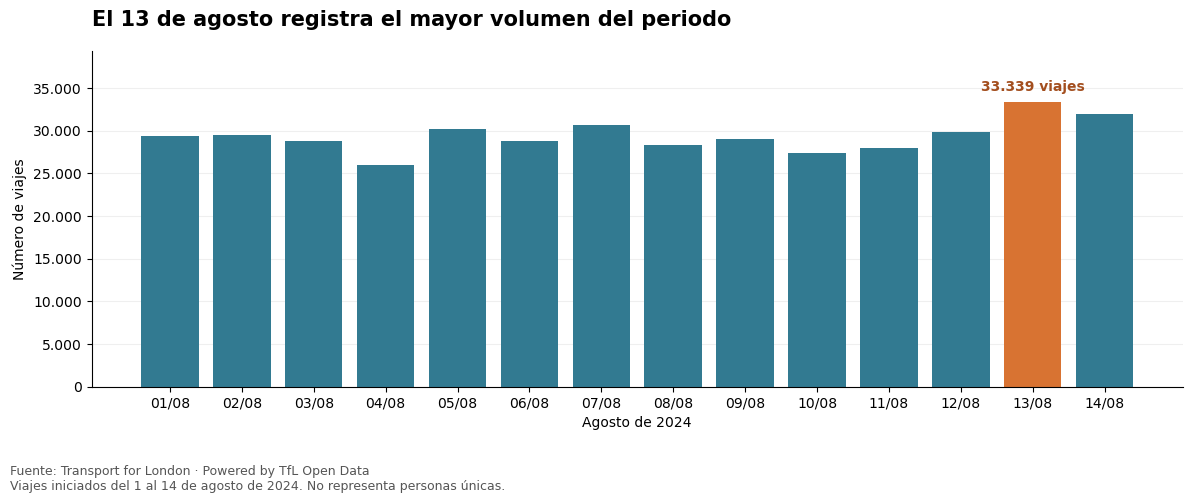

In [111]:
import matplotlib.ticker as ticker

# Preparar fechas y localizar el día con más viajes.
fechas = pd.to_datetime(viajes_diarios["fecha"])
cantidades = viajes_diarios["viajes"].to_numpy()
pos_maximo = cantidades.argmax()

colores = ["#327A91"] * len(cantidades)
colores[pos_maximo] = "#D87332"

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(range(len(cantidades)), cantidades, color=colores)

ax.set_xticks(range(len(cantidades)))
ax.set_xticklabels(fechas.dt.strftime("%d/%m"))
ax.set_ylabel("Número de viajes")
ax.set_xlabel("Agosto de 2024")
ax.set_ylim(0, cantidades.max() * 1.18)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", "."))
)

ax.set_title(
    "El 13 de agosto registra el mayor volumen del periodo",
    loc="left", fontsize=15, fontweight="bold", pad=18
)

ax.annotate(
    f"{cantidades[pos_maximo]:,} viajes".replace(",", "."),
    xy=(pos_maximo, cantidades[pos_maximo]),
    xytext=(0, 8),
    textcoords="offset points",
    ha="center",
    fontweight="bold",
    color="#A34E1E"
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Fuente: Transport for London · Powered by TfL Open Data\n"
    "Viajes iniciados del 1 al 14 de agosto de 2024. No representa personas únicas.",
    fontsize=9, color="#555555"
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

El volumen diario no muestra cómo se distribuye el uso dentro de cada jornada. Se desglosan los viajes por hora y tipo de día. Se lleva a cabo el desglose respecto a franjas horarias diarias

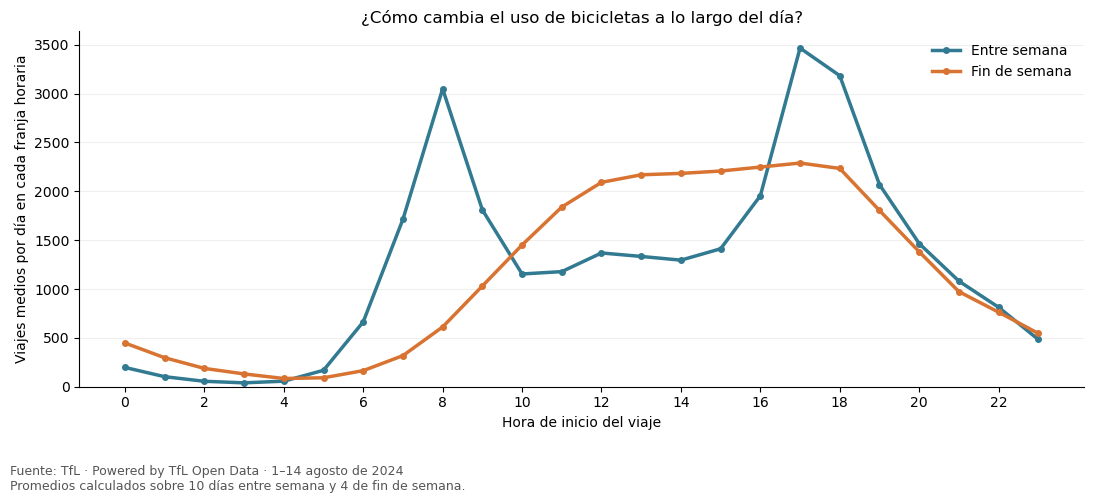

In [112]:
# Preparación temporal para comparar patrones horarios.
horarios = datos.assign(
    fecha=datos["fecha_inicio"].dt.date,
    hora=datos["fecha_inicio"].dt.hour,
    tipo_dia=datos["fecha_inicio"].dt.dayofweek.map(
        lambda dia: "Entre semana" if dia < 5 else "Fin de semana"
    )
)

# Incluir las 24 horas de cada fecha, incluso si alguna no tiene viajes.
fechas_periodo = sorted(horarios["fecha"].unique())
indice = pd.MultiIndex.from_product(
    [fechas_periodo, range(24)],
    names=["fecha", "hora"]
)

conteos = (
    horarios.groupby(["fecha", "hora"])
    .size()
    .reindex(indice, fill_value=0)
    .rename("viajes")
    .reset_index()
)

conteos["tipo_dia"] = pd.to_datetime(conteos["fecha"]).dt.dayofweek.map(
    lambda dia: "Entre semana" if dia < 5 else "Fin de semana"
)

perfil_horario = (
    conteos.groupby(["hora", "tipo_dia"])["viajes"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(11, 5))

for grupo, color in [
    ("Entre semana", "#327A91"),
    ("Fin de semana", "#D87332")
]:
    ax.plot(
        perfil_horario.index,
        perfil_horario[grupo],
        label=grupo,
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=4
    )

ax.set(
    title="¿Cómo cambia el uso de bicicletas a lo largo del día?",
    xlabel="Hora de inicio del viaje",
    ylabel="Viajes medios por día en cada franja horaria",
    xticks=range(0, 24, 2),
    ylim=(0, None)
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Fuente: TfL · Powered by TfL Open Data · 1–14 agosto de 2024\n"
    "Promedios calculados sobre 10 días entre semana y 4 de fin de semana.",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

### Interpretación del patrón horario

- Entre semana se observan picos de viajes iniciados a las 08 h y a las 17 h.
- El fin de semana presenta una actividad más sostenida entre mediodía y tarde.
- El patrón sugiere revisar la disponibilidad y la distribución de bicicletas
  en distintas franjas según el tipo de día.
- Los datos no permiten confirmar los motivos de los desplazamientos
  ni determinar cuántas bicicletas adicionales serían necesarias.
- Resultados limitados al periodo del 1 al 14 de agosto de 2024.

Copia para CHORD

In [113]:
# Partimos de la tabla original cargada, sin filtrar por duración.
datos_chord = viajes.copy()

datos_chord["fecha_inicio"] = pd.to_datetime(
    datos_chord["Start date"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

# Comprobar los campos necesarios para analizar conexiones.
campos_necesarios = [
    "Start station number",
    "End station number",
    "fecha_inicio"
]

assert datos_chord[campos_necesarios].notna().all().all(), (
    "Hay valores ausentes o fechas no interpretables que debemos revisar."
)

print(f"Viajes disponibles para el chord: {len(datos_chord):,}")

Viajes disponibles para el chord: 411,370


Estaciones distintas

In [114]:
estaciones_origen = set(datos_chord["Start station number"])
estaciones_destino = set(datos_chord["End station number"])

estaciones_total = estaciones_origen | estaciones_destino

print(f"Estaciones de origen: {len(estaciones_origen):,}")
print(f"Estaciones de destino: {len(estaciones_destino):,}")
print(f"Estaciones distintas en total: {len(estaciones_total):,}")

print(
    "Presentes como origen y destino:",
    len(estaciones_origen & estaciones_destino)
)

print(
    "Solo aparecen como origen:",
    len(estaciones_origen - estaciones_destino)
)

print(
    "Solo aparecen como destino:",
    len(estaciones_destino - estaciones_origen)
)

Estaciones de origen: 799
Estaciones de destino: 803
Estaciones distintas en total: 803
Presentes como origen y destino: 799
Solo aparecen como origen: 0
Solo aparecen como destino: 4


Nombres de estaciones y variaciones

In [115]:
catalogo_estaciones = pd.concat([
    datos_chord[
        ["Start station number", "Start station"]
    ].rename(columns={
        "Start station number": "id_estacion",
        "Start station": "estacion"
    }),

    datos_chord[
        ["End station number", "End station"]
    ].rename(columns={
        "End station number": "id_estacion",
        "End station": "estacion"
    })
], ignore_index=True)

catalogo_estaciones["estacion"] = (
    catalogo_estaciones["estacion"].str.strip()
)

variantes_nombre = (
    catalogo_estaciones.groupby("id_estacion")["estacion"]
    .nunique()
)

ids_con_variantes = variantes_nombre[variantes_nombre > 1].index

print(
    "Identificadores asociados a más de un nombre:",
    len(ids_con_variantes)
)

if len(ids_con_variantes) > 0:
    display(
        catalogo_estaciones[
            catalogo_estaciones["id_estacion"].isin(ids_con_variantes)
        ]
        .drop_duplicates()
        .sort_values(["id_estacion", "estacion"])
    )

# Como etiqueta, utilizar el nombre más frecuente de cada identificador.
nombres_estaciones = (
    catalogo_estaciones
    .groupby(["id_estacion", "estacion"])
    .size()
    .reset_index(name="apariciones")
    .sort_values(
        ["id_estacion", "apariciones", "estacion"],
        ascending=[True, False, True]
    )
    .drop_duplicates("id_estacion")
    .set_index("id_estacion")[["estacion"]]
)

Identificadores asociados a más de un nombre: 0


Actividad por estación

In [116]:
salidas = (
    datos_chord.groupby("Start station number")
    .size()
    .rename("salidas")
)

llegadas = (
    datos_chord.groupby("End station number")
    .size()
    .rename("llegadas")
)

actividad_estaciones = (
    pd.concat([salidas, llegadas], axis=1)
    .fillna(0)
    .astype(int)
)

actividad_estaciones.index.name = "id_estacion"

actividad_estaciones["movimientos"] = (
    actividad_estaciones["salidas"]
    + actividad_estaciones["llegadas"]
)

actividad_estaciones = (
    actividad_estaciones
    .join(nombres_estaciones)
    .reset_index()
    .sort_values(
        ["movimientos", "id_estacion"],
        ascending=[False, True]
    )
)

display(
    actividad_estaciones[
        ["id_estacion", "estacion", "salidas", "llegadas", "movimientos"]
    ].head(30)
)

,id_estacion,estacion,salidas,llegadas,movimientos
110,1075,"Hyde Park Corner, Hyde Park",4822,4404,9226
164,1132,"Albert Gate, Hyde Park",3266,3198,6464
188,1157,"Black Lion Gate, Kensington Gardens",2704,2725,5429
242,1217,"Serpentine Car Park, Hyde Park",2186,2170,4356
123,1088,"Triangle Car Park, Hyde Park",2141,2102,4243
1,960,"Hop Exchange, The Borough",1728,2138,3866
107,1072,"Waterloo Station 3, Waterloo",1868,1934,3802
668,300021,"Podium, Queen Elizabeth Olympic Park",1856,1903,3759
259,2587,"Wormwood Street, Liverpool Street",1758,1776,3534
598,200202,"Storey's Gate, Westminster",1683,1808,3491


Existe un volumen muy elevado de estaciones y de viajes en cada una de ellas, por lo que parece que al distirbución no es muy desigual en el top20 de mayores paradas. Se lleva a cabo la evaluación por distritos, contemplando la posibilidad de agrupar las paradas por distrito, para mejorar la visualización a nivel de argo/agrupación cetegórica

Incorporación de datos geográficos (tfl_agosto_2024)

In [117]:
# Inventario geográfico de estaciones publicado por TfL en 2023.
ruta_estaciones = proyecto / "data" / "raw" / "estaciones_tfl_2023.csv"

estaciones_geo = pd.read_csv(ruta_estaciones, encoding="cp1252")

print(f"Registros: {len(estaciones_geo):,}")
print("Columnas:", estaciones_geo.columns.tolist())

display(estaciones_geo.head())

Registros: 811
Columnas: ['StationName', 'longitude', 'latitude', 'Easting', 'Northing']


,StationName,longitude,latitude,Easting,Northing
0,"Abbey Orchard Street, Westminster",-0.132102,51.4981,529755.520,179341.070
1,"Abbotsbury Road, Holland Park",-0.205991,51.5014,524619.340,179576.680
2,"Aberdeen Place, St. John's Wood",-0.176268,51.5248,526598.677,182219.159
3,"Aberfeldy Street, Poplar",-0.005659,51.5135,538483.968,181285.264
4,"Abingdon Green, Westminster",-0.125978,51.4976,530187.151,179296.365


Comparación fuente de datos viajes con estaciones, y evaluación de diferencias

In [118]:
# Normalizar nombres sin modificar los campos originales.
def normalizar_nombre(serie):
    return (
        serie.astype("string")
        .str.normalize("NFKC")
        .str.strip()
        .str.casefold()
        .str.replace("’", "'", regex=False)
        .str.replace(r"\s+", " ", regex=True)
    )

# Todas las combinaciones de identificador y nombre de nuestros viajes.
estaciones_viajes = pd.concat([
    datos_chord[
        ["Start station number", "Start station"]
    ].rename(columns={
        "Start station number": "id_estacion",
        "Start station": "estacion"
    }),
    datos_chord[
        ["End station number", "End station"]
    ].rename(columns={
        "End station number": "id_estacion",
        "End station": "estacion"
    })
], ignore_index=True).drop_duplicates()

estaciones_viajes["nombre_normalizado"] = normalizar_nombre(
    estaciones_viajes["estacion"]
)

geo_revision = estaciones_geo.copy()
geo_revision["nombre_normalizado"] = normalizar_nombre(
    geo_revision["StationName"]
)

# Detectar nombres repetidos antes de unir las tablas.
duplicados_geo = geo_revision["nombre_normalizado"].duplicated(
    keep=False
)

print(
    "Registros geográficos con nombres repetidos:",
    duplicados_geo.sum()
)

if duplicados_geo.any():
    display(geo_revision.loc[duplicados_geo])

# Primera comprobación de cobertura por nombre.
estaciones_viajes["coincide_nombre"] = (
    estaciones_viajes["nombre_normalizado"]
    .isin(geo_revision["nombre_normalizado"].dropna())
)

cobertura = (
    estaciones_viajes.groupby("id_estacion")["coincide_nombre"]
    .any()
)

print(f"Estaciones distintas en los viajes: {len(cobertura):,}")
print(f"Con coincidencia de nombre: {cobertura.sum():,}")
print(f"Sin coincidencia: {(~cobertura).sum():,}")
print(f"Cobertura inicial: {cobertura.mean():.2%}")

# Mostrar las estaciones para las que no encontramos ningún nombre.
ids_sin_coincidencia = cobertura[~cobertura].index

display(
    estaciones_viajes.loc[
        estaciones_viajes["id_estacion"].isin(ids_sin_coincidencia),
        ["id_estacion", "estacion"]
    ].sort_values("estacion")
)

Registros geográficos con nombres repetidos: 0
Estaciones distintas en los viajes: 803
Con coincidencia de nombre: 755
Sin coincidencia: 48
Cobertura inicial: 94.02%


,id_estacion,estacion
198,3429444,"Abbey Orchard Street, Westminster_OLD"
1973,1019,"Ampton Street , Clerkenwell"
517,1011,"Argyle Street, Kings Cross"
457,964,"Bath Street, St. Lke's"
445,1006,"Bayley Street , Bloomsbury"
881,1166,"Bell Street , Marylebone"
3205,1066,"Calshot Street , King's Cross"
8547,22181,"Camley Street, Camden Town"
782,1010,"Cartwright Gardens , Bloomsbury"
132,300006,"Clapham South, Clapham South"


In [119]:
# Identificadores con al menos una coincidencia de nombre.
ids_localizados = set(cobertura[cobertura].index)

origen_localizado = datos_chord["Start station number"].isin(
    ids_localizados
)
destino_localizado = datos_chord["End station number"].isin(
    ids_localizados
)

ambos_localizados = origen_localizado & destino_localizado

resumen_cobertura = pd.DataFrame({
    "Situación": [
        "Origen y destino localizados",
        "Solo origen localizado",
        "Solo destino localizado",
        "Ningún extremo localizado"
    ],
    "Viajes": [
        ambos_localizados.sum(),
        (origen_localizado & ~destino_localizado).sum(),
        (~origen_localizado & destino_localizado).sum(),
        (~origen_localizado & ~destino_localizado).sum()
    ]
})

resumen_cobertura["Porcentaje"] = (
    resumen_cobertura["Viajes"] / len(datos_chord) * 100
).round(2)

display(resumen_cobertura)

# Priorizar las estaciones pendientes con mayor actividad.
pendientes = actividad_estaciones.loc[
    ~actividad_estaciones["id_estacion"].isin(ids_localizados),
    ["id_estacion", "estacion", "salidas", "llegadas", "movimientos"]
].sort_values("movimientos", ascending=False)

display(pendientes.head(20))

,Situación,Viajes,Porcentaje
0,Origen y destino localizados,362441,88.11
1,Solo origen localizado,22674,5.51
2,Solo destino localizado,23091,5.61
3,Ningún extremo localizado,3164,0.77


,id_estacion,estacion,salidas,llegadas,movimientos
50,1011,"Argyle Street, Kings Cross",1595,1541,3136
74,1037,"Park Lane , Hyde Park",1563,1566,3129
89,1052,"Soho Square , Soho",1394,1685,3079
474,200064,"Regent's Row , Haggerston",1212,1217,2429
106,1071,"Tower Gardens , Tower",1149,1152,2301
5,964,"Bath Street, St. Lke's",843,837,1680
229,1202,"Wellington Street , Strand",815,823,1638
177,1145,"Earnshaw Street , Covent Garden",808,820,1628
109,1074,"Newgate Street , St. Paul's",761,827,1588
201,1171,"New Road 1 , Whitechapel",731,753,1484


Normalización de formato

In [120]:
#Uniformar espacios alrededor de las comas en ambos archivos.
estaciones_viajes["nombre_normalizado"] = (
    estaciones_viajes["nombre_normalizado"]
    .str.replace(r"\s*,\s*", ", ", regex=True)
)

geo_revision["nombre_normalizado"] = (
    geo_revision["nombre_normalizado"]
    .str.replace(r"\s*,\s*", ", ", regex=True)
)

# Revisar si la normalización genera nombres duplicados.
duplicados_geo = geo_revision["nombre_normalizado"].duplicated(
    keep=False
)

print(
    "Registros geográficos con nombres repetidos:",
    duplicados_geo.sum()
)

if duplicados_geo.any():
    display(
        geo_revision.loc[duplicados_geo]
        .sort_values("nombre_normalizado")
    )

# Admitir solo nombres que identifican un único registro geográfico.
nombres_geo_unicos = geo_revision.loc[
    ~duplicados_geo, "nombre_normalizado"
].dropna()

estaciones_viajes["coincide_nombre"] = (
    estaciones_viajes["nombre_normalizado"]
    .isin(nombres_geo_unicos)
)

cobertura = (
    estaciones_viajes.groupby("id_estacion")["coincide_nombre"]
    .any()
)

print(f"Estaciones con coincidencia: {cobertura.sum():,}")
print(f"Estaciones pendientes: {(~cobertura).sum():,}")
print(f"Cobertura de estaciones: {cobertura.mean():.2%}")

Registros geográficos con nombres repetidos: 0
Estaciones con coincidencia: 793
Estaciones pendientes: 10
Cobertura de estaciones: 98.75%


Busqueda de coincidencias de nombre y formato

In [121]:
# Buscar candidatos para revisión manual.
# Esta celda solo muestra información: no modifica las correspondencias.
busquedas = [
    "Argyle",
    "Bath Street",
    "Leonard Circus",
    "Abbey Orchard",
    "Clapham South",
    "Elgin",
    "Westbourne",
    "Camley",
    "Mechanical Workshop"
]

for texto in busquedas:
    candidatos = geo_revision.loc[
        geo_revision["StationName"].str.contains(
            texto, case=False, regex=False, na=False
        ),
        ["StationName", "longitude", "latitude"]
    ]

    print(f"\nBúsqueda: {texto}")

    if candidatos.empty:
        print("Sin candidatos en el inventario de 2023.")
    else:
        display(candidatos)


Búsqueda: Argyle
Sin candidatos en el inventario de 2023.

Búsqueda: Bath Street


,StationName,longitude,latitude
46,"Bath Street, St. Luke's",-0.0908478,51.5259



Búsqueda: Leonard Circus


,StationName,longitude,latitude
419,"Leonard Circus, Shoreditch",-0.0844393,51.5247



Búsqueda: Abbey Orchard


,StationName,longitude,latitude
0,"Abbey Orchard Street, Westminster",-0.132102,51.4981



Búsqueda: Clapham South
Sin candidatos en el inventario de 2023.

Búsqueda: Elgin
Sin candidatos en el inventario de 2023.

Búsqueda: Westbourne


,StationName,longitude,latitude
784,"Westbourne Grove, Bayswater",-0.190241,51.5155
785,"Westbourne Park Road, Portobello",-0.201005,51.5179



Búsqueda: Camley
Sin candidatos en el inventario de 2023.

Búsqueda: Mechanical Workshop
Sin candidatos en el inventario de 2023.


Aplicación correspondencia Bath Street

In [122]:
# Clave de enlace independiente del nombre original.
estaciones_viajes["nombre_enlace"] = (
    estaciones_viajes["nombre_normalizado"]
)

# Correspondencia manual propuesta por diferencia de escritura.
nombre_bath = geo_revision.loc[
    geo_revision["StationName"].eq("Bath Street, St. Luke's"),
    "nombre_normalizado"
]

assert len(nombre_bath) == 1, "Revisar el candidato de Bath Street."

estaciones_viajes.loc[
    estaciones_viajes["id_estacion"].eq(964),
    "nombre_enlace"
] = nombre_bath.iloc[0]

# Actualizar la cobertura.
estaciones_viajes["coincide_nombre"] = (
    estaciones_viajes["nombre_enlace"].isin(nombres_geo_unicos)
)

cobertura = (
    estaciones_viajes.groupby("id_estacion")["coincide_nombre"]
    .any()
)

print(f"Estaciones con coincidencia: {cobertura.sum():,}")
print(f"Estaciones pendientes: {(~cobertura).sum():,}")

Estaciones con coincidencia: 794
Estaciones pendientes: 9


Se normalizaron espacios y se incorporó una correspondencia manual por diferencia de escritura en Bath Street. Las estaciones sin correspondencia y los casos _OLD permanecen pendientes, sin asignarles ubicaciones por semejanza de nombre.

Se añaden las coordenadas

In [123]:
# Unir cada nombre de estación con el inventario geográfico.
estaciones_coordenadas = estaciones_viajes.merge(
    geo_revision[
        ["nombre_normalizado", "longitude", "latitude"]
    ],
    left_on="nombre_enlace",
    right_on="nombre_normalizado",
    how="left",
    validate="many_to_one",
    suffixes=("", "_geo")
)

# Conservar las correspondencias con ambas coordenadas.
localizadas = estaciones_coordenadas.dropna(
    subset=["longitude", "latitude"]
).copy()

# Comprobar que cada identificador tiene una sola ubicación.
ubicaciones_por_id = (
    localizadas[
        ["id_estacion", "longitude", "latitude"]
    ]
    .drop_duplicates()
    .groupby("id_estacion")
    .size()
)

assert ubicaciones_por_id.le(1).all(), (
    "Hay identificadores asociados a varias ubicaciones: revisar."
)

# Una fila por estación localizada.
estaciones_mapa = (
    localizadas[
        ["id_estacion", "estacion", "longitude", "latitude"]
    ]
    .drop_duplicates("id_estacion")
    .reset_index(drop=True)
)

print(f"Estaciones con coordenadas: {len(estaciones_mapa):,}")
display(estaciones_mapa.head())

Estaciones con coordenadas: 794


,id_estacion,estacion,longitude,latitude
0,22165,"Fisherman's Walk West, Canary Wharf",-0.02296,51.5062
1,22159,"Ebury Bridge, Pimlico",-0.149186,51.4905
2,1072,"Waterloo Station 3, Waterloo",-0.113864,51.504
3,300237,"Tate Modern, Bankside",-0.098884952,51.50672097
4,300249,"Westminster Pier, Westminster",-0.12382352,51.501513


Han sido incorporadas las coordenadas a las estaciones, ahora solamente falta introducir información acerca de las limitaciones por distrito

In [124]:
import geopandas as gpd

ruta_distritos = proyecto / "data" / "raw" / "distritos_londres.gpkg"
distritos = gpd.read_file(ruta_distritos)

print(f"Áreas administrativas: {len(distritos)}")
print("Sistema de coordenadas:", distritos.crs)
print("Columnas:", distritos.columns.tolist())

display(distritos.head())

Áreas administrativas: 33
Sistema de coordenadas: EPSG:27700
Columnas: ['objectid', 'name', 'gss_code', 'hectares', 'nonld_area', 'ons_inner', 'sub_2011', 'geometry']


,objectid,name,gss_code,hectares,nonld_area,ons_inner,sub_2011,geometry
0,1,Kingston upon Thames,E09000021,3726.117,0.000,F,South,"POLYGON ((516401.6 160201.8, 516407.3 160210.5..."
1,2,Croydon,E09000008,8649.441,0.000,F,South,"POLYGON ((535009.2 159504.7, 535005.5 159502, ..."
2,3,Bromley,E09000006,15013.487,0.000,F,South,"POLYGON ((540373.6 157530.4, 540361.2 157551.9..."
3,4,Hounslow,E09000018,5658.541,60.755,F,West,"POLYGON ((509703.4 175356.6, 509712.6 175361.8..."
4,5,Ealing,E09000009,5554.428,0.000,F,West,"POLYGON ((515647.2 178787.8, 515608.8 178787.3..."


In [125]:
# Convertir las coordenadas a valores numéricos.
estaciones_puntos = estaciones_mapa.copy()

for columna in ["longitude", "latitude"]:
    texto = (
        estaciones_puntos[columna]
        .astype("string")
        .str.strip()
        .str.replace("\u200b", "", regex=False)
        .str.replace("\ufeff", "", regex=False)
        .str.replace("\u2212", "-", regex=False)
    )

    numeros = pd.to_numeric(texto, errors="coerce")

    # Mostrar cualquier valor que siga sin poder interpretarse.
    invalidos = numeros.isna()

    if invalidos.any():
        display(
            estaciones_puntos.loc[
                invalidos, ["id_estacion", "estacion", columna]
            ]
        )
        raise ValueError(
            f"Quedan coordenadas no interpretables en {columna}."
        )

    estaciones_puntos[columna] = numeros

# Crear puntos geográficos y usar el mismo sistema que los distritos.
estaciones_puntos = gpd.GeoDataFrame(
    estaciones_puntos,
    geometry=gpd.points_from_xy(
        estaciones_puntos["longitude"],
        estaciones_puntos["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(distritos.crs)

# Asignar el distrito que contiene cada estación.
estaciones_distrito = gpd.sjoin(
    estaciones_puntos,
    distritos[["name", "gss_code", "geometry"]].rename(
        columns={"name": "distrito"}
    ),
    how="left",
    predicate="within"
)

# Comprobar que ninguna estación recibe varias asignaciones.
assert not estaciones_distrito["id_estacion"].duplicated().any(), (
    "Hay estaciones asignadas a varios distritos: revisar."
)

sin_distrito = estaciones_distrito["distrito"].isna()

print(f"Estaciones evaluadas: {len(estaciones_distrito):,}")
print(f"Con distrito asignado: {(~sin_distrito).sum():,}")
print(f"Sin distrito asignado: {sin_distrito.sum():,}")

# Incluir también las áreas sin estaciones localizadas.
conteo = (
    estaciones_distrito.dropna(subset=["gss_code"])
    .groupby("gss_code")["id_estacion"]
    .nunique()
    .rename("estaciones")
    .reset_index()
)

resumen_distritos = (
    distritos[["gss_code", "name"]]
    .rename(columns={"name": "distrito"})
    .merge(conteo, on="gss_code", how="left", validate="one_to_one")
)

resumen_distritos["estaciones"] = (
    resumen_distritos["estaciones"].fillna(0).astype(int)
)

resumen_distritos = resumen_distritos.sort_values(
    "estaciones", ascending=False
)

display(resumen_distritos)

if sin_distrito.any():
    display(
        estaciones_distrito.loc[
            sin_distrito,
            ["id_estacion", "estacion", "longitude", "latitude"]
        ]
    )

Estaciones evaluadas: 794
Con distrito asignado: 793
Sin distrito asignado: 1


,gss_code,distrito,estaciones
25,E09000033,Westminster,169
27,E09000030,Tower Hamlets,118
23,E09000020,Kensington and Chelsea,93
26,E09000007,Camden,62
21,E09000013,Hammersmith and Fulham,59
20,E09000032,Wandsworth,59
15,E09000022,Lambeth,58
22,E09000028,Southwark,58
24,E09000001,City of London,38
29,E09000012,Hackney,37


,id_estacion,estacion,longitude,latitude
163,300207,"Gauden Road, Clapham",51.464995,-0.130909


In [126]:
# Revisar el caso sin distrito y la estación asignada a Croydon.
casos_revision = estaciones_distrito.loc[
    estaciones_distrito["distrito"].isna()
    | estaciones_distrito["distrito"].eq("Croydon"),
    ["id_estacion", "estacion", "longitude", "latitude", "distrito"]
]

display(casos_revision)

,id_estacion,estacion,longitude,latitude,distrito
163,300207,"Gauden Road, Clapham",51.464995,-0.130909,NaN
184,200241,"Bonner Gate, Victoria Park",-0.049592,51.3341,Croydon


In [127]:
# Consultar ambas representaciones de las coordenadas originales.
revision_geo = geo_revision.loc[
    geo_revision["StationName"].str.contains(
        r"Gauden Road|Bonner Gate",
        case=False,
        regex=True,
        na=False
    ),
    ["StationName", "longitude", "latitude", "Easting", "Northing"]
].copy()

display(revision_geo)

,StationName,longitude,latitude,Easting,Northing
84,"Bonner Gate, Victoria Park",-0.0495918,51.3341,535379.0,183414.0
278,"Gauden Road, Clapham",51.464995,-0.1309089,529933.0,175659.0


In [128]:
# Preparar las coordenadas británicas de los dos casos.
comparacion = revision_geo.copy()

for columna in ["Easting", "Northing"]:
    comparacion[columna] = pd.to_numeric(
        comparacion[columna].astype("string").str.strip(),
        errors="raise"
    )

# Convertir de British National Grid a longitud y latitud.
puntos_revision = gpd.GeoDataFrame(
    comparacion,
    geometry=gpd.points_from_xy(
        comparacion["Easting"],
        comparacion["Northing"]
    ),
    crs="EPSG:27700"
).to_crs("EPSG:4326")

comparacion["longitud_desde_EN"] = puntos_revision.geometry.x
comparacion["latitud_desde_EN"] = puntos_revision.geometry.y

display(
    comparacion[
        [
            "StationName",
            "longitude",
            "latitude",
            "longitud_desde_EN",
            "latitud_desde_EN"
        ]
    ]
)

,StationName,longitude,latitude,longitud_desde_EN,latitud_desde_EN
84,"Bonner Gate, Victoria Park",-0.0495918,51.3341,-0.049590,51.533408
278,"Gauden Road, Clapham",51.464995,-0.1309089,-0.130915,51.464995


In [129]:
# Corregir solo estos dos casos en la tabla de trabajo.
# Fuente: conversión de Easting/Northing del mismo inventario.
casos_corregidos = {
    300207: "Gauden Road, Clapham",
    200241: "Bonner Gate, Victoria Park"
}

for id_estacion, nombre in casos_corregidos.items():
    candidato = comparacion.loc[
        comparacion["StationName"].eq(nombre)
    ]

    assert len(candidato) == 1, f"Revisar correspondencia: {nombre}"

    fila = candidato.iloc[0]
    mascara = estaciones_mapa["id_estacion"].eq(id_estacion)

    assert mascara.sum() == 1, f"Revisar identificador: {id_estacion}"

    estaciones_mapa.loc[mascara, "longitude"] = (
        fila["longitud_desde_EN"]
    )
    estaciones_mapa.loc[mascara, "latitude"] = (
        fila["latitud_desde_EN"]
    )

In [130]:
# Convertir las coordenadas a valores numéricos.
estaciones_puntos = estaciones_mapa.copy()

for columna in ["longitude", "latitude"]:
    texto = (
        estaciones_puntos[columna]
        .astype("string")
        .str.strip()
        .str.replace("\u200b", "", regex=False)
        .str.replace("\ufeff", "", regex=False)
        .str.replace("\u2212", "-", regex=False)
    )

    numeros = pd.to_numeric(texto, errors="coerce")

    # Mostrar cualquier valor que siga sin poder interpretarse.
    invalidos = numeros.isna()

    if invalidos.any():
        display(
            estaciones_puntos.loc[
                invalidos, ["id_estacion", "estacion", columna]
            ]
        )
        raise ValueError(
            f"Quedan coordenadas no interpretables en {columna}."
        )

    estaciones_puntos[columna] = numeros

# Crear puntos geográficos y usar el mismo sistema que los distritos.
estaciones_puntos = gpd.GeoDataFrame(
    estaciones_puntos,
    geometry=gpd.points_from_xy(
        estaciones_puntos["longitude"],
        estaciones_puntos["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(distritos.crs)

# Asignar el distrito que contiene cada estación.
estaciones_distrito = gpd.sjoin(
    estaciones_puntos,
    distritos[["name", "gss_code", "geometry"]].rename(
        columns={"name": "distrito"}
    ),
    how="left",
    predicate="within"
)

# Comprobar que ninguna estación recibe varias asignaciones.
assert not estaciones_distrito["id_estacion"].duplicated().any(), (
    "Hay estaciones asignadas a varios distritos: revisar."
)

sin_distrito = estaciones_distrito["distrito"].isna()

print(f"Estaciones evaluadas: {len(estaciones_distrito):,}")
print(f"Con distrito asignado: {(~sin_distrito).sum():,}")
print(f"Sin distrito asignado: {sin_distrito.sum():,}")

# Incluir también las áreas sin estaciones localizadas.
conteo = (
    estaciones_distrito.dropna(subset=["gss_code"])
    .groupby("gss_code")["id_estacion"]
    .nunique()
    .rename("estaciones")
    .reset_index()
)

resumen_distritos = (
    distritos[["gss_code", "name"]]
    .rename(columns={"name": "distrito"})
    .merge(conteo, on="gss_code", how="left", validate="one_to_one")
)

resumen_distritos["estaciones"] = (
    resumen_distritos["estaciones"].fillna(0).astype(int)
)

resumen_distritos = resumen_distritos.sort_values(
    "estaciones", ascending=False
)

display(resumen_distritos)

if sin_distrito.any():
    display(
        estaciones_distrito.loc[
            sin_distrito,
            ["id_estacion", "estacion", "longitude", "latitude"]
        ]
    )

Estaciones evaluadas: 794
Con distrito asignado: 794
Sin distrito asignado: 0


,gss_code,distrito,estaciones
25,E09000033,Westminster,169
27,E09000030,Tower Hamlets,119
23,E09000020,Kensington and Chelsea,93
26,E09000007,Camden,62
20,E09000032,Wandsworth,59
15,E09000022,Lambeth,59
21,E09000013,Hammersmith and Fulham,59
22,E09000028,Southwark,58
24,E09000001,City of London,38
29,E09000012,Hackney,37


In [131]:
# Correspondencia única entre estación y distrito.
mapa_distritos = estaciones_distrito.set_index("id_estacion")["distrito"]

viajes_distritos = datos_chord.copy()

viajes_distritos["distrito_origen"] = (
    viajes_distritos["Start station number"].map(mapa_distritos)
)

viajes_distritos["distrito_destino"] = (
    viajes_distritos["End station number"].map(mapa_distritos)
)

# Para analizar conexiones necesitamos ambos extremos asignados.
ambos_asignados = viajes_distritos[
    ["distrito_origen", "distrito_destino"]
].notna().all(axis=1)

viajes_geo = viajes_distritos.loc[ambos_asignados].copy()

print(f"Viajes con ambos distritos: {len(viajes_geo):,}")
print(f"Cobertura: {ambos_asignados.mean():.2%}")

# Distinguir viajes dentro de un distrito y entre distritos.
viajes_geo["interno"] = (
    viajes_geo["distrito_origen"]
    == viajes_geo["distrito_destino"]
)

resumen_flujos = pd.DataFrame({
    "Tipo": ["Dentro del mismo distrito", "Entre distritos"],
    "Viajes": [
        viajes_geo["interno"].sum(),
        (~viajes_geo["interno"]).sum()
    ]
})

resumen_flujos["porcentaje"] = (
    resumen_flujos["Viajes"] / len(viajes_geo) * 100
).round(2)

display(resumen_flujos)

Viajes con ambos distritos: 403,095
Cobertura: 97.99%


,Tipo,Viajes,porcentaje
0,Dentro del mismo distrito,169903,42.15
1,Entre distritos,233192,57.85


Las estaciones localizadas se agrupan en 12 distritos administrativos. Los sectores del chord representan los distritos y las bandas agregan los viajes desde el distrito de origen al de destino. Se incluyen los viajes internos. El análisis cubre el 97,99 % de los viajes del periodo; el 2,01 % restante no tiene ambos extremos localizados.

In [132]:
# Comparativa de viajes laboraboes y fin de semana
# Clasificar todos los viajes, incluidos los pendientes de localización.
viajes_distritos["tipo_dia"] = (
    viajes_distritos["fecha_inicio"].dt.dayofweek
    .map(lambda d: "Entre semana" if d < 5 else "Fin de semana")
)

viajes_distritos["fecha"] = (
    viajes_distritos["fecha_inicio"].dt.normalize()
)

# Denominadores calculados sobre todos los viajes del periodo.
resumen_comparacion = (
    viajes_distritos.groupby("tipo_dia")
    .agg(
        viajes_totales=("Number", "size"),
        dias=("fecha", "nunique")
    )
)

# Seleccionar únicamente viajes con ambos distritos.
viajes_geo = viajes_distritos.dropna(
    subset=["distrito_origen", "distrito_destino"]
).copy()

viajes_geo["interno"] = (
    viajes_geo["distrito_origen"]
    == viajes_geo["distrito_destino"]
)

resumen_geo = (
    viajes_geo.groupby("tipo_dia")
    .agg(
        viajes_localizados=("Number", "size"),
        viajes_internos=("interno", "sum")
    )
)

resumen_comparacion = resumen_comparacion.join(resumen_geo)

resumen_comparacion["cobertura_pct"] = (
    resumen_comparacion["viajes_localizados"]
    / resumen_comparacion["viajes_totales"] * 100
)

resumen_comparacion["viajes_localizados_por_dia"] = (
    resumen_comparacion["viajes_localizados"]
    / resumen_comparacion["dias"]
)

resumen_comparacion["internos_pct_localizados"] = (
    resumen_comparacion["viajes_internos"]
    / resumen_comparacion["viajes_localizados"] * 100
)

display(resumen_comparacion.round(2))

# Tabla de conexiones dirigidas para los futuros chord.
flujos_chord = (
    viajes_geo.groupby(
        ["tipo_dia", "distrito_origen", "distrito_destino"]
    )
    .size()
    .reset_index(name="viajes")
)

flujos_chord["dias"] = flujos_chord["tipo_dia"].map(
    resumen_comparacion["dias"]
)

flujos_chord["viajes_medios_por_dia"] = (
    flujos_chord["viajes"] / flujos_chord["dias"]
)

display(
    flujos_chord.sort_values(
        ["tipo_dia", "viajes_medios_por_dia"],
        ascending=[True, False]
    ).head(15)
)

,viajes_totales,dias,viajes_localizados,viajes_internos,cobertura_pct,viajes_localizados_por_dia,internos_pct_localizados
tipo_dia,,,,,,,
Entre semana,301174,10,294589,118419,97.81,29458.9,40.20
Fin de semana,110196,4,108506,51484,98.47,27126.5,47.45


,tipo_dia,distrito_origen,distrito_destino,viajes,dias,viajes_medios_por_dia
143,Entre semana,Westminster,Westminster,38047,10,3804.7
117,Entre semana,Tower Hamlets,Tower Hamlets,21697,10,2169.7
65,Entre semana,Kensington and Chelsea,Kensington and Chelsea,12542,10,1254.2
71,Entre semana,Kensington and Chelsea,Westminster,9127,10,912.7
137,Entre semana,Westminster,Kensington and Chelsea,9119,10,911.9
39,Entre semana,Hammersmith and Fulham,Hammersmith and Fulham,7825,10,782.5
104,Entre semana,Southwark,Southwark,7626,10,762.6
0,Entre semana,Camden,Camden,7503,10,750.3
130,Entre semana,Wandsworth,Wandsworth,7124,10,712.4
11,Entre semana,Camden,Westminster,6456,10,645.6


In [133]:
for tipo in ["Entre semana", "Fin de semana"]:
    print(f"\n{tipo}: conexiones principales entre distritos")

    principales = flujos_chord.loc[
        flujos_chord["tipo_dia"].eq(tipo)
        & flujos_chord["distrito_origen"].ne(
            flujos_chord["distrito_destino"]
        )
    ].sort_values("viajes_medios_por_dia", ascending=False)

    display(
        principales[
            [
                "distrito_origen",
                "distrito_destino",
                "viajes",
                "viajes_medios_por_dia"
            ]
        ].head(10)
    )


Entre semana: conexiones principales entre distritos


,distrito_origen,distrito_destino,viajes,viajes_medios_por_dia
71,Kensington and Chelsea,Westminster,9127,912.7
137,Westminster,Kensington and Chelsea,9119,911.9
11,Camden,Westminster,6456,645.6
132,Westminster,Camden,6203,620.3
138,Westminster,Lambeth,4678,467.8
83,Lambeth,Westminster,4471,447.1
109,Tower Hamlets,City of London,4288,428.8
63,Kensington and Chelsea,Hammersmith and Fulham,3749,374.9
80,Lambeth,Southwark,3479,347.9
21,City of London,Tower Hamlets,3425,342.5



Fin de semana: conexiones principales entre distritos


,distrito_origen,distrito_destino,viajes,viajes_medios_por_dia
279,Westminster,Kensington and Chelsea,4010,1002.50
215,Kensington and Chelsea,Westminster,3996,999.00
155,Camden,Westminster,2217,554.25
274,Westminster,Camden,2146,536.50
177,Hackney,Tower Hamlets,1522,380.50
253,Tower Hamlets,Hackney,1498,374.50
207,Kensington and Chelsea,Hammersmith and Fulham,1449,362.25
185,Hammersmith and Fulham,Kensington and Chelsea,1416,354.00
280,Westminster,Lambeth,1393,348.25
227,Lambeth,Westminster,1284,321.00


In [134]:
carpeta_exportacion = proyecto / "data" / "processed"
carpeta_exportacion.mkdir(parents=True, exist_ok=True)

archivos = {
    "Entre semana": "chord_entre_semana.csv",
    "Fin de semana": "chord_fin_de_semana.csv"
}

for tipo, nombre_archivo in archivos.items():
    tabla = (
        flujos_chord.loc[
            flujos_chord["tipo_dia"].eq(tipo),
            [
                "distrito_origen",
                "distrito_destino",
                "viajes_medios_por_dia"
            ]
        ]
        .rename(columns={
            "distrito_origen": "origen",
            "distrito_destino": "destino",
            "viajes_medios_por_dia": "viajes_por_dia"
        })
        .sort_values(["origen", "destino"])
    )

    tabla.to_csv(
        carpeta_exportacion / nombre_archivo,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Guardado: {nombre_archivo} — {len(tabla)} conexiones")

Guardado: chord_entre_semana.csv — 144 conexiones
Guardado: chord_fin_de_semana.csv — 142 conexiones


Calculo de saldo de bicis por tipo de día

In [135]:
# Salidas por distrito y tipo de día.
salidas_distrito = (
    viajes_geo.groupby(["tipo_dia", "distrito_origen"])
    .size()
    .rename("salidas")
    .rename_axis(index=["tipo_dia", "distrito"])
)

# Llegadas por distrito y tipo de día.
# El tipo de día corresponde al inicio del viaje.
llegadas_distrito = (
    viajes_geo.groupby(["tipo_dia", "distrito_destino"])
    .size()
    .rename("llegadas")
    .rename_axis(index=["tipo_dia", "distrito"])
)

balance_distritos = (
    pd.concat([salidas_distrito, llegadas_distrito], axis=1)
    .fillna(0)
    .astype(int)
    .reset_index()
)

balance_distritos["dias"] = balance_distritos["tipo_dia"].map(
    resumen_comparacion["dias"]
)

balance_distritos["saldo"] = (
    balance_distritos["llegadas"] - balance_distritos["salidas"]
)

for columna in ["salidas", "llegadas", "saldo"]:
    balance_distritos[f"{columna}_por_dia"] = (
        balance_distritos[columna] / balance_distritos["dias"]
    )

# Cada viaje aporta una salida y una llegada:
# la suma de los saldos de todos los distritos debe ser cero.
assert (
    balance_distritos.groupby("tipo_dia")["saldo"].sum().eq(0).all()
), "Revisar los recuentos de salidas y llegadas."

for tipo in ["Entre semana", "Fin de semana"]:
    print(f"\n{tipo}")

    display(
        balance_distritos.loc[
            balance_distritos["tipo_dia"].eq(tipo),
            [
                "distrito",
                "salidas_por_dia",
                "llegadas_por_dia",
                "saldo_por_dia"
            ]
        ]
        .sort_values("saldo_por_dia")
        .round(2)
    )


Entre semana


,distrito,salidas_por_dia,llegadas_por_dia,saldo_por_dia
4,Islington,1245.1,1138.3,-106.8
2,Hackney,1378.1,1298.0,-80.1
9,Tower Hamlets,3761.8,3693.4,-68.4
6,Lambeth,2347.6,2306.9,-40.7
0,Camden,2376.6,2342.7,-33.9
5,Kensington and Chelsea,3030.9,2998.3,-32.6
10,Wandsworth,1692.4,1694.3,1.9
3,Hammersmith and Fulham,1623.0,1626.1,3.1
7,Newham,259.4,266.7,7.3
8,Southwark,2286.6,2311.6,25.0



Fin de semana


,distrito,salidas_por_dia,llegadas_por_dia,saldo_por_dia
23,Westminster,7474.75,7401.25,-73.50
14,Hackney,1381.75,1333.50,-48.25
17,Kensington and Chelsea,3152.25,3126.50,-25.75
16,Islington,958.75,933.50,-25.25
12,Camden,1798.00,1776.75,-21.25
21,Tower Hamlets,3955.75,3942.25,-13.50
19,Newham,399.75,409.00,9.25
18,Lambeth,1785.25,1799.25,14.00
15,Hammersmith and Fulham,1514.25,1529.25,15.00
13,City of London,1019.00,1042.25,23.25


Los flujos y saldos observados permiten identificar distritos prioritarios para estudiar la redistribución de bicicletas y la disponibilidad. Las diferencias entre semana y fin de semana sugieren que la planificación logística podría adaptarse al tipo de día. Estos resultados orientan el diagnóstico, pero no permiten determinar cantidades concretas de reposición ni necesidades de almacenamiento. 
Para ello necesitamos información  adicional sobre capacidad, disponibilidad y movimientos del servicio.

In [136]:
#Exportación de los saldos por distrito y tipo de día.

carpeta_exportacion = proyecto / "data" / "processed"
carpeta_exportacion.mkdir(parents=True, exist_ok=True)

archivos_balance = {
    "Entre semana": "balance_distritos_entre_semana.csv",
    "Fin de semana": "balance_distritos_fin_de_semana.csv"
}

for tipo, nombre_archivo in archivos_balance.items():
    tabla_balance = (
        balance_distritos.loc[
            balance_distritos["tipo_dia"].eq(tipo),
            [
                "distrito",
                "salidas_por_dia",
                "llegadas_por_dia",
                "saldo_por_dia"
            ]
        ]
        .sort_values("distrito")
    )

    tabla_balance.to_csv(
        carpeta_exportacion / nombre_archivo,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Guardado: {nombre_archivo}")

Guardado: balance_distritos_entre_semana.csv
Guardado: balance_distritos_fin_de_semana.csv


RIDGELINE (planteamiento)
«¿Cómo cambia la distribución de la duración de los viajes según el día de la semana?»
- Eje horizontal: duración en minutos.
- Filas: lunes a domingo.
- Altura de las curvas: densidad; muestra dónde se concentran las duraciones, no el volumen de viajes.
- Color: distinguir entre semana y fin de semana.
- Datos: viajes de 1 a 120 minutos, conservando 404.340 registros, el 98,29 %.
- Comparación: misma escala horizontal y mismo criterio de suavizado para todas las curvas.
Siete filas permitirán observar diferencias dentro de cada grupo, además del contraste entre semana y fin de semana.

In [137]:
orden_dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

resumen_ridgeline = (
    datos_ridgeline.groupby("dia_semana")["duracion_min"]
    .agg(
        viajes="size",
        mediana="median",
        percentil_25=lambda x: x.quantile(0.25),
        percentil_75=lambda x: x.quantile(0.75),
        percentil_90=lambda x: x.quantile(0.90)
    )
    .reindex(orden_dias)
)

display(resumen_ridgeline.round(2))

,viajes,mediana,percentil_25,percentil_75,percentil_90
dia_semana,,,,,
Lunes,59043,14.11,8.35,22.14,31.75
Martes,61240,13.89,8.31,21.90,30.88
Miércoles,61872,13.72,8.16,21.60,30.90
Jueves,56998,13.42,8.04,20.99,29.69
Viernes,57543,14.08,8.30,22.32,32.00
Sábado,54976,15.98,9.09,25.04,36.95
Domingo,52668,16.32,9.39,25.51,38.81


el fin de semana las duraciones son mayores y más dispersas.
- Mediana entre semana: entre 13,42 y 14,11 minutos.
- Sábado y domingo: 15,98 y 16,32 minutos.
- Percentil 90: alrededor de 30–32 minutos entre semana, frente a 36,95 el sábado y 38,81 el domingo.

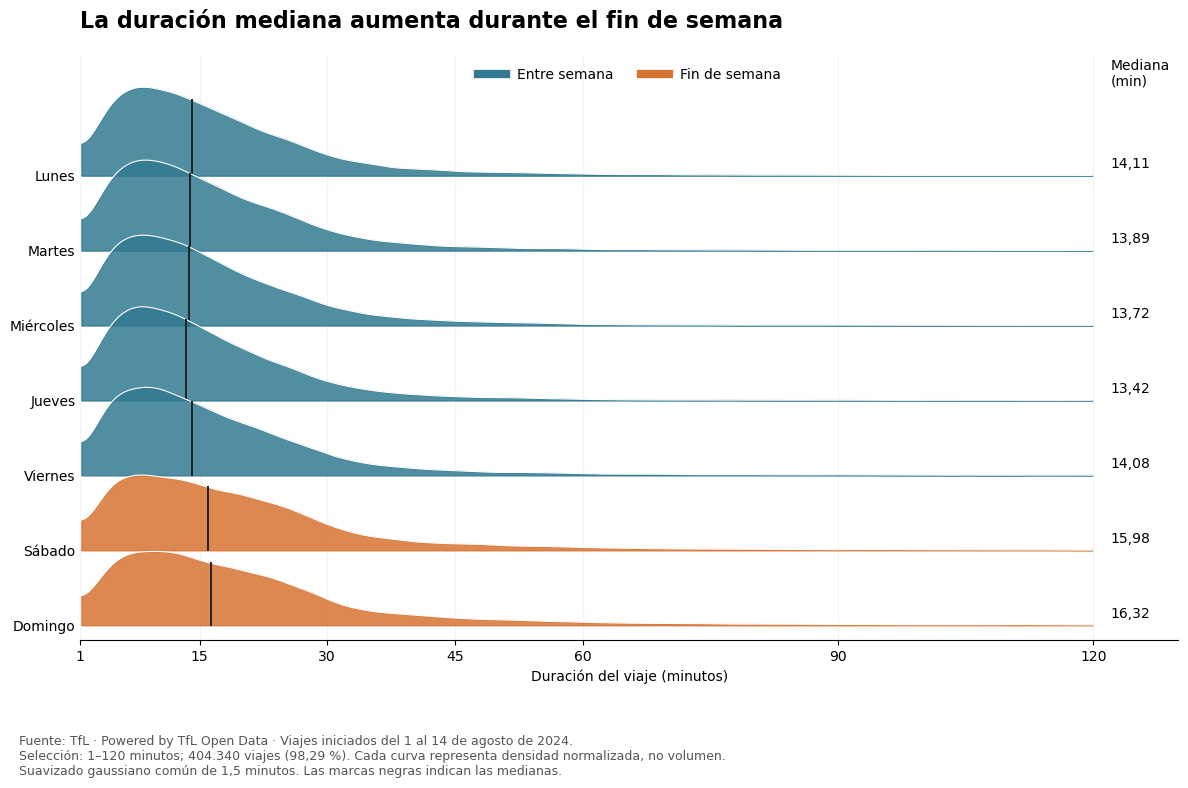

In [138]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

orden_dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

# Histograma fino y suavizado gaussiano común.
# Evitamos necesitar bibliotecas adicionales.
bordes = np.linspace(1, 120, 477)
x = (bordes[:-1] + bordes[1:]) / 2
paso = bordes[1] - bordes[0]

ancho_suavizado = 1.5  # minutos, igual para todos los días
radio = int(np.ceil(4 * ancho_suavizado / paso))
distancias = np.arange(-radio, radio + 1) * paso

kernel = np.exp(-0.5 * (distancias / ancho_suavizado) ** 2)
kernel /= kernel.sum()

curvas = {}

for dia in orden_dias:
    valores = datos_ridgeline.loc[
        datos_ridgeline["dia_semana"].eq(dia), "duracion_min"
    ].dropna()

    densidad, _ = np.histogram(valores, bins=bordes, density=True)

    # Reflexión en los límites del intervalo seleccionado.
    extendida = np.pad(densidad, radio, mode="symmetric")
    suavizada = np.convolve(extendida, kernel, mode="valid")
    suavizada /= suavizada.sum() * paso

    curvas[dia] = suavizada

# Un único factor de escala: no igualamos los picos de cada curva.
factor = 1.25 / max(curva.max() for curva in curvas.values())

fig, ax = plt.subplots(figsize=(12, 8))
colores = {"Entre semana": "#327A91", "Fin de semana": "#D87332"}

for i, dia in enumerate(orden_dias):
    base = len(orden_dias) - 1 - i
    grupo = "Fin de semana" if dia in ["Sábado", "Domingo"] else "Entre semana"
    color = colores[grupo]
    altura = curvas[dia] * factor

    ax.fill_between(
        x, base, base + altura,
        color=color, alpha=0.85, zorder=i + 2
    )
    ax.plot(
        x, base + altura,
        color="white", linewidth=0.8, zorder=i + 2
    )

    mediana = resumen_ridgeline.loc[dia, "mediana"]
    altura_mediana = np.interp(mediana, x, altura)

    ax.plot(
        [mediana, mediana],
        [base, base + altura_mediana],
        color="#222222", linewidth=1.4, zorder=i + 3
    )

    etiqueta = f"{mediana:.2f}".replace(".", ",")
    ax.text(122, base + 0.15, etiqueta, va="center", fontsize=10)

ax.set_yticks(range(7))
ax.set_yticklabels(orden_dias[::-1])
ax.set_xlim(1, 130)
ax.set_ylim(-0.2, 7.6)
ax.set_xticks([1, 15, 30, 45, 60, 90, 120])
ax.set_xlabel("Duración del viaje (minutos)")
ax.set_title(
    "La duración mediana aumenta durante el fin de semana",
    loc="left", fontsize=16, weight="bold", pad=20
)
ax.text(122, 7.2, "Mediana\n(min)", fontsize=10, ha="left")

ax.legend(
    handles=[
        Line2D([0], [0], color=colores["Entre semana"], lw=6,
               label="Entre semana"),
        Line2D([0], [0], color=colores["Fin de semana"], lw=6,
               label="Fin de semana")
    ],
    loc="upper center", frameon=False, ncol=2
)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

for borde in ["top", "right", "left"]:
    ax.spines[borde].set_visible(False)

fig.text(
    0.02, 0.025,
    "Fuente: TfL · Powered by TfL Open Data · Viajes iniciados del 1 al 14 de agosto de 2024.\n"
    "Selección: 1–120 minutos; 404.340 viajes (98,29 %). "
    "Cada curva representa densidad normalizada, no volumen.\n"
    "Suavizado gaussiano común de 1,5 minutos. Las marcas negras indican las medianas.",
    fontsize=9, color="#555555"
)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

La mayor duración de los viajes durante el fin de semana sugiere explorar modalidades tarifarias que incluyan más tiempo de uso, como un pase específico. La visualización permite identificar esta oportunidad de evaluación, pero no determinar el precio adecuado ni garantizar una mejora para los usuarios o el servicio. Para ello sería necesario conocer las tarifas utilizadas, las preferencias de los clientes y su respuesta a posibles cambios.

In [139]:
carpeta_figuras = proyecto / "docs" / "assets"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta_figuras / "ridgeline_duracion.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    carpeta_figuras / "ridgeline_duracion.svg",
    bbox_inches="tight",
    facecolor="white"
)

print("Ridgeline guardado en PNG y SVG.")

Ridgeline guardado en PNG y SVG.


In [140]:
# Importación data para infografía

carpeta_exportacion = proyecto / "data" / "processed"
carpeta_exportacion.mkdir(parents=True, exist_ok=True)

viajes_diarios.to_csv(
    carpeta_exportacion / "infografia_viajes_diarios.csv",
    index=False,
    encoding="utf-8-sig"
)

perfil_horario.reset_index().to_csv(
    carpeta_exportacion / "infografia_perfil_horario.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Exportados los viajes diarios y los perfiles horarios.")

Exportados los viajes diarios y los perfiles horarios.


In [141]:
tabla_diaria = viajes_diarios.copy()
fechas = pd.to_datetime(tabla_diaria["fecha"])

# Etiquetas cortas, conservando el orden cronológico.
tabla_diaria["fecha"] = fechas.dt.strftime("%d/%m")

# Categoría que utilizaremos para asignar colores.
tabla_diaria["tipo_dia"] = fechas.dt.dayofweek.map(
    lambda dia: "Entre semana" if dia < 5 else "Fin de semana"
)

tabla_diaria.to_csv(
    carpeta_exportacion / "infografia_viajes_diarios.csv",
    index=False,
    encoding="utf-8-sig"
)

display(tabla_diaria)

,fecha,viajes,tipo_dia
0,01/08,29430,Entre semana
1,02/08,29491,Entre semana
2,03/08,28792,Fin de semana
3,04/08,26024,Fin de semana
4,05/08,30250,Entre semana
5,06/08,28759,Entre semana
6,07/08,30651,Entre semana
7,08/08,28375,Entre semana
8,09/08,29001,Entre semana
9,10/08,27356,Fin de semana
